In [48]:
# Problem 1(b)
def bisection_method(func, interval, tolerance=1e-8, max_iterations=100):
   a, b = interval
   if func(a) * func(b) >= 0:
       raise ValueError("The function must have opposite signs at the endpoints of the interval.")
   iteration = 0
   while (b - a) / 2 > tolerance and iteration < max_iterations:
       c = (a + b) / 2 # Midpoint
       if func(c) == 0: # Exact root found
           return c,iteration,(b-a)
       elif func(a) * func(c) < 0:
           b = c # Replace b with c
       else:
           a = c # Replace a with c
       iteration += 1
   return (a + b) / 2,iteration,(b-a) / 2 # Returns root, n, and error bound

In [50]:
# Problem 1(c) (inspired from example from class)
f = lambda x: x**2 - 1
true_r = 1 
initial_bracket = [0.2, 1.2]

# 2. Call existing bisection method
x_n, n, error_bound = bisection_method(f, initial_bracket, tolerance=1e-8)

# 3. Calculates the true errors
abs_error = abs(x_n - true_r)
rel_error = abs_error / abs(true_r)

# 4. Output of exact variables
print(f"Iteration (n): {n}")
print(f"Midpoint (x_n): {x_n}")
print(f"Absolute Error: {abs_error}")
print(f"Relative Error: {rel_error}")
print(f"Error Bound: {error_bound}")

# 5. Confirms numerically that the absolute error does not exceed the bound
print(f"Verification: {abs_error} <= {error_bound} is {abs_error <= error_bound}")

Iteration (n): 26
Midpoint (x_n): 1.0000000044703483
Absolute Error: 4.470348313745376e-09
Relative Error: 4.470348313745376e-09
Error Bound: 7.450580596923828e-09
Verification: 4.470348313745376e-09 <= 7.450580596923828e-09 is True


In [52]:
#Problem 2(b)
def f(x):
    return x**3 - 6

def f_prime(x):
    return 3*x**2

def newtons_method(f, f_prime, x0, tol=1e-12, max_iter=50):
    x = x0
    for n in range(1, max_iter + 1):
        x_new = x - f(x)/f_prime(x)
        
        #Stopping criteria
        eta_n = abs(x_new - x) / max(1, abs(x_new))
        
        if eta_n <= tol:
            return x_new, n, eta_n
            
        x = x_new
        
    return x, max_iter, eta_n

# Chain it from your bisection method
x0_bisection, _, _ = bisection_method(f, [1, 2], tolerance=1e-3)

# Run Newton's method using that x0
root, iterations, final_eta = newtons_method(f, f_prime, x0=x0_bisection)

# The true root for x^3 - 6 = 0
true_root = 6**(1/3)

rel_error = abs(root - true_root) / abs(true_root)

print(f"Root: {root}, Iterations: {iterations}, eta_n: {final_eta}, Final True Relative Error: {rel_error}")

Root: 1.8171205928321397, Iterations: 3, eta_n: 4.887834209813353e-16, Final True Relative Error: 0.0


In [54]:
def f(x):
    return (x - 1)**2

def df(x):
    return 2 * (x - 1)

def newton_multiple_root(x0, tol=1e-8, max_iter=100):
    x_prev = x0
    
    for n in range(1, max_iter + 1):
        x_curr = x_prev - f(x_prev) / df(x_prev)
        
        # Stopping criterion: |x_n - x_{n-1}| <= 10^-8
        if abs(x_curr - x_prev) <= tol:
            error_curr = abs(x_curr - 1)
            error_prev = abs(x_prev - 1)
            ratio = error_curr / error_prev
            return n, x_curr, error_curr, ratio
            
        x_prev = x_curr
        
    error_curr = abs(x_curr - 1)
    error_prev = abs(x_prev - 1)
    ratio = error_curr / error_prev
    return max_iter, x_curr, error_curr, ratio

# Run with initial guess x0 = 3
n, x_n, final_error, final_ratio = newton_multiple_root(3.0, tol=1e-8)


print(f"Iterations (n): {n}")
print(f"Final Approximation (x_n): {x_n}")
print(f"Final Error |x_n - 1|: {final_error}")
print(f"Final Ratio: {final_ratio}")

Iterations (n): 28
Final Approximation (x_n): 1.0000000074505806
Final Error |x_n - 1|: 7.450580596923828e-09
Final Ratio: 0.5


In [56]:
#Problem 2(d)
import math

def f(x):
    return x**2 - 11

# 1. Modified bisection to return the final bracket [a, b]
def bisection_get_bracket(f, a, b, tol=1e-3):
    while (b - a) / 2.0 > tol:
        c = (a + b) / 2.0
        if f(a) * f(c) < 0:
            b = c
        else:
            a = c
    return a, b


def secant_method(f, x0, x1, tol=1e-10, max_iter=50):
    x_prev2 = x0
    x_prev1 = x1
    
    # We start counting at n=2 because x0 and x1 are already our first two points
    for n in range(2, max_iter + 2):
        f_p1 = f(x_prev1)
        f_p2 = f(x_prev2)
        
        # Secant iteration formula
        x_curr = x_prev1 - f_p1 * (x_prev1 - x_prev2) / (f_p1 - f_p2)
        
        # Hybrid stopping criterion
        eta_n = abs(x_curr - x_prev1) / max(1, abs(x_curr))
        
        if eta_n <= tol:
            return n, x_curr, eta_n
            
        x_prev2 = x_prev1
        x_prev1 = x_curr
        
    return max_iter, x_curr, eta_n

# 3. Execution
a, b = bisection_get_bracket(f, 3.0, 4.0, tol=1e-3)
n, x_n, eta_n = secant_method(f, x0=a, x1=b, tol=1e-10)

# 4. True relative error
true_r = math.sqrt(11)
rel_error = abs(x_n - true_r) / abs(true_r)

print(f"Bisection Bracket (x0, x1): [{a}, {b}]")
print(f"Iterations (n): {n}")
print(f"Final Approximation (x_n): {x_n}")
print(f"Stopping Criterion (eta_n): {eta_n}")
print(f"True Relative Error: {rel_error}")

Bisection Bracket (x0, x1): [3.31640625, 3.318359375]
Iterations (n): 4
Final Approximation (x_n): 3.3166247903554
Stopping Criterion (eta_n): 4.503657036135901e-12
True Relative Error: 0.0


In [58]:
#Problem 4(b)
def f(x):
    return math.sin(x) - x

def df(x):
    return math.cos(x) - 1

def newton_multiple_root(x0, tol=1e-10, max_iter=100):
    x = x0
    for n in range(1, max_iter + 1):
        x_new = x - f(x) / df(x)
        
        # True absolute error since r = 0
        error = abs(x_new - 0)
        
        if error <= tol:
            return n, x_new, error
            
        x = x_new
        
    return max_iter, x, abs(x - 0)

# Run with initial guess x0 = 0.5
n, x_n, final_error = newton_multiple_root(0.5, tol=1e-10)

print(f"Iterations (n): {n}")
print(f"Final Approximation (x_n): {x_n}")
print(f"Final True Absolute Error: {final_error}")

Iterations (n): 100
Final Approximation (x_n): 1.9811533808897018e-08
Final True Absolute Error: 1.9811533808897018e-08


<>:40: SyntaxWarning: invalid escape sequence '\s'
<>:40: SyntaxWarning: invalid escape sequence '\s'
C:\Users\danta\AppData\Local\Temp\ipykernel_13648\605127498.py:40: SyntaxWarning: invalid escape sequence '\s'
  plt.title('Newton\'s Method Convergence on $f(x) = \sin(x) - x$ (Multiple Root)')


Iterations (n): 100
Final Approximation (x_n): 1.9811533808897018e-08
Final True Absolute Error: 1.9811533808897018e-08



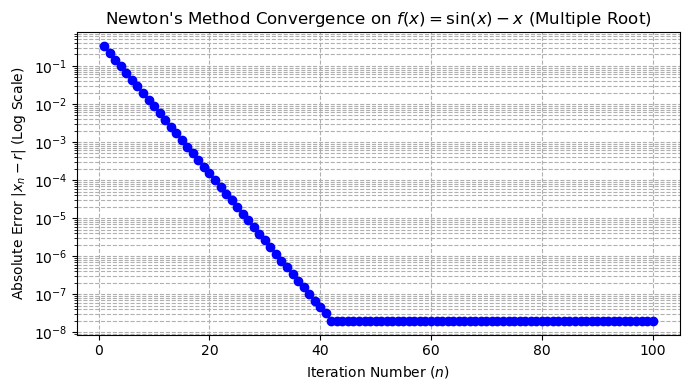

In [60]:
import math
import matplotlib.pyplot as plt

def f(x):
    return math.sin(x) - x

def df(x):
    return math.cos(x) - 1

def newton_multiple_root(x0, tol=1e-10, max_iter=100):
    x = x0
    errors = []
    
    for n in range(1, max_iter + 1):
        x_new = x - f(x) / df(x)
        error = abs(x_new - 0)
        errors.append(error)
        
        # Check stopping criteria
        if error <= tol:
            return n, x_new, error, errors
            
        x = x_new
        
    return max_iter, x, abs(x - 0), errors

# Run the simulation starting at x0 = 0.5
n, x_n, final_error, errors = newton_multiple_root(0.5, tol=1e-10)


print(f"Iterations (n): {n}")
print(f"Final Approximation (x_n): {x_n}")
print(f"Final True Absolute Error: {final_error}\n")


plt.figure(figsize=(7, 4))
plt.semilogy(range(1, len(errors) + 1), errors, marker='o', linestyle='-', color='b')
plt.xlabel('Iteration Number ($n$)')
plt.ylabel('Absolute Error $|x_n - r|$ (Log Scale)')
plt.title('Newton\'s Method Convergence on $f(x) = \sin(x) - x$ (Multiple Root)')
plt.grid(True, which="both", ls="--")
plt.tight_layout()
plt.show()

In [61]:
#Problem 3(f)
def stable_newton(x0, tol=1e-16, max_iter=100):
    x = x0
    for n in range(1, max_iter + 1):
        # Stable numerator: use Taylor series for sin(x) - x when x is small
        if abs(x) < 1e-4:
            num = -(x**3) / 6.0 + (x**5) / 120.0
        else:
            num = math.sin(x) - x
            
        # Stable denominator: use half-angle identity for cos(x) - 1
        den = -2.0 * (math.sin(x / 2.0)**2)
        
        if den == 0:
            break
            
        x_new = x - num / den
        error = abs(x_new - 0)
        
        if error <= tol:
            return n, x_new, error
            
        x = x_new
        
    return max_iter, x, abs(x - 0)

# Run the modified method starting at x0 = 0.5
n, x_n, final_error = stable_newton(0.5)


print(f"Iterations (n): {n}")
print(f"Final Approximation (x_n): {x_n}")
print(f"Final True Absolute Error: {final_error}")

Iterations (n): 90
Final Approximation (x_n): 7.038653286859629e-17
Final True Absolute Error: 7.038653286859629e-17
